# S03 · 从「天」到「事件」：游程理论与 declustering

> **Day 3 / 14** ｜ 对应论文章节 **3.4（Event identification）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 用游程（run）语言精确描述「热浪」
- 解释 `min_len` 和 `max_gap` 分别在控制什么，以及它们为什么互相拉扯
- 给出事件的四个属性：duration / intensity / severity / peak
- 处理缺测日，避免它把两个事件「缝」成一个

---

## 1. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}

d <- load_clean_daily()
STATION <- "Kuantan"
s <- d %>% filter(station == STATION) %>% arrange(date)
s <- s[format(s$date, "%m-%d") != "02-29", ]

doy <- as.integer(format(s$date, "%j"))
yr  <- as.integer(format(s$date, "%Y"))

th <- daily_threshold(doy, s$tmax, yr)
s$threshold <- th[doy]
s$exceed    <- s$tmax > s$threshold

cat("超阈值日数:", sum(s$exceed, na.rm = TRUE),
    "（占", round(mean(s$exceed, na.rm = TRUE) * 100, 1), "%）\n")


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


超阈值日数: 1519 （占 9.6 %）


---

## 2. 游程理论

**一个热浪 = 一段连续的超阈值日。**

用 `rle()`（run-length encoding）把 `TRUE/FALSE` 序列压缩成「值 + 长度」：

In [2]:
# 注意：s$exceed 里有 NA（缺测日）。rle() 会把 NA 当成一个独立取值，
# 直接 runs[runs$value, ] 会产生一批全是 NA 的行 —— 后面 decluster 会炸。
# 正确处理：先把 NA 显式转成 FALSE（缺测日不算超阈值），并单独记下位置。
ex_flag <- s$exceed
na_idx  <- which(is.na(ex_flag))
ex_flag[na_idx] <- FALSE

r <- rle(ex_flag)
runs <- data.frame(
  value  = r$values,
  start  = cumsum(r$lengths) - r$lengths + 1,
  end    = cumsum(r$lengths),
  length = r$lengths
)
runs <- runs[runs$value, ]
runs$start_date <- s$date[runs$start]
runs$end_date   <- s$date[runs$end]

cat("缺测日数:", length(na_idx), "\n")

cat("原始超阈值片段数:", nrow(runs), "\n")
print(head(runs[, c("start_date", "end_date", "length")], 8))

缺测日数: 172 


原始超阈值片段数: 805 


   start_date   end_date length
2  1980-01-15 1980-01-15      1
4  1980-02-04 1980-02-05      2
6  1980-04-13 1980-04-13      1
8  1980-04-25 1980-04-28      4
10 1980-08-02 1980-08-02      1
12 1980-08-12 1980-08-12      1
14 1980-09-16 1980-09-18      3
16 1980-09-22 1980-09-22      1


In [3]:
# 游程长度的分布 —— 你会看到大量 1 天的"碎片"
print(table(pmin(runs$length, 10)))


  1   2   3   4   5   6   7   8   9  10 
460 170  84  38  27  14   5   4   2   1 


> 📌 **关键观察**：绝大多数片段只有 1–2 天。如果不设最短持续时间，你的「热浪」会有一半是单日高温 —— 这不是热浪，这是天气。

---

## 3. `min_len`：最短持续

In [4]:
runs$keep_minlen <- runs$length >= CFG$min_len
cat(sprintf("设 min_len = %d 天后，保留 %d / %d 个片段\n",
            CFG$min_len, sum(runs$keep_minlen), nrow(runs)))

设 min_len = 3 天后，保留 175 / 805 个片段


> 为什么是 3 天？
> - Perkins & Alexander (2013) 指出 3 天是「人体热负荷开始累积」的经验阈值
> - WMO 的热浪定义普遍用 3 天
> - 太短 → 混入天气噪声；太长 → 样本量不足（每个站可能只剩十几次事件）
>
> **这个数字必须是可调的**，S03 最后一节会给敏感性表。

---

## 4. `max_gap`：declustering（去聚类）

热浪常见形态：

```
[热 热 热] [缓 1 天] [热 热]      ← 中间断了一天，但物理上是一个事件
```

如果不合并，它会被算成 2 个事件：一个 3 天、一个 2 天 —— **时长被系统性低估，事件数被系统性高估**。

In [5]:
# 找出所有"两个片段之间只隔 1-2 天"的例子
gaps <- data.frame(
  gap_days = runs$start[-1] - runs$end[-nrow(runs)] - 1,
  first    = runs$end_date[-nrow(runs)],
  second   = runs$start_date[-1]
)
print(head(gaps[gaps$gap_days <= 3, ], 10))

   gap_days      first     second
7         3 1980-09-18 1980-09-22
10        3 1980-10-28 1980-11-01
12        3 1980-12-09 1980-12-13
30        1 1982-08-06 1982-08-08
39        2 1983-06-26 1983-06-29
40        1 1983-06-29 1983-07-01
41        1 1983-07-01 1983-07-03
45        1 1983-10-26 1983-10-28
60        1 1985-01-03 1985-01-05
61        3 1985-01-05 1985-01-09


In [6]:
# 应用 declustering 前后对比
runs_kept <- runs[runs$keep_minlen, ]
ev_decl   <- decluster(
  data.frame(value = TRUE, start = runs_kept$start,
             end = runs_kept$end, length = runs_kept$length),
  min_len = CFG$min_len, max_gap = CFG$max_gap
)

cat(sprintf("min_len 后片段数 : %d\n", nrow(runs_kept)))
cat(sprintf("decluster 后事件数: %d\n", nrow(ev_decl)))
cat(sprintf("被合并掉的片段   : %d\n", nrow(runs_kept) - nrow(ev_decl)))

min_len 后片段数 : 175


decluster 后事件数: 169


被合并掉的片段   : 6


---

## 5. 缺测日必须硬性切断

如果中间有一天是 `NA`，`NA > threshold` 得到 `NA`，我们把它当 `FALSE` 处理。但 **declustering 会把这段 `FALSE` 当成「间隔 1 天」而把两侧合并** —— 用缺失数据把两个事件缝在一起。

In [7]:
# 看看数据里有多少"事件内部含缺测日"
ev0 <- extract_events(s, "tmax", defn = "Tmax")
cat("含缺测日的事件数:", sum(ev0$n_missing > 0), " / ", nrow(ev0), "\n")

含缺测日的事件数: 0  /  90 


`00_setup.R` 里的 `split_at_gaps()` 就是在 decluster 之后，把所有跨越 `NA` 的片段重新切开：

In [8]:
bad <- which(is.na(s$tmax))
cat("缺测日数:", length(bad), "\n")

缺测日数: 161 


> ⚠️ 真数据里缺测可能成片出现（仪器故障）。如果一段 10 天的缺测正好落在热浪中间，正确处理是：**这个事件的信息不完整，应标记为低质量**，而不是假装它连续。

---

## 6. 事件的四个属性

| 属性 | 定义 | 用途 |
|---|---|---|
| **duration** `D` | 事件持续天数 | copula 的维度 1 |
| **intensity** `I` | `max(值 − 阈值)`，即峰值**超出量** | copula 的维度 2 |
| **severity** `S` | `Σ max(值 − 阈值, 0)`，累积超出量 | 描述性统计 |
| **peak_value** | 事件期间的绝对最高值 | 报告用 |

> 🔍 **为什么 intensity 用「超出量」而不是「绝对温度」？**
> 因为绝对温度跨站不可比（高原站 25 °C 可能就是极端，低地站 35 °C 才极端）。超出量是**相对于当地气候**的度量，跨站可比。

In [9]:
ev <- extract_events(s, "tmax", defn = "Tmax")
cat("事件数:", nrow(ev), "\n")
print(head(ev[, c("start_date", "end_date", "duration",
                  "peak_value", "threshold_at_peak", "intensity", "severity")], 6))

事件数: 90 


  start_date   end_date duration peak_value threshold_at_peak intensity
1 1980-04-25 1980-04-27        3       36.5          35.60000  0.900000
2 1981-08-14 1981-08-16        3       36.5          34.90000  1.600000
3 1983-07-21 1983-07-23        3       36.8          35.42333  1.376667
4 1983-11-03 1983-11-07        5       35.4          33.40000  2.000000
5 1985-09-12 1985-09-15        4       35.9          34.30000  1.600000
6 1985-10-05 1985-10-12        8       36.2          34.20000  2.000000
   severity
1  2.513333
2  2.700000
3  3.476667
4  6.596667
5  3.976667
6 10.000000


In [10]:
summary(ev[, c("duration", "intensity", "severity")])

    duration        intensity        severity      
 Min.   : 3.000   Min.   :0.500   Min.   : 0.9067  
 1st Qu.: 3.000   1st Qu.:1.179   1st Qu.: 2.5350  
 Median : 4.000   Median :1.550   Median : 3.6750  
 Mean   : 4.456   Mean   :1.623   Mean   : 4.3941  
 3rd Qu.: 5.000   3rd Qu.:2.000   3rd Qu.: 5.0650  
 Max.   :13.000   Max.   :3.600   Max.   :16.0767  

---

## 7. 画出来看：一年的超阈值日与事件

事件最多的年份: 2006 


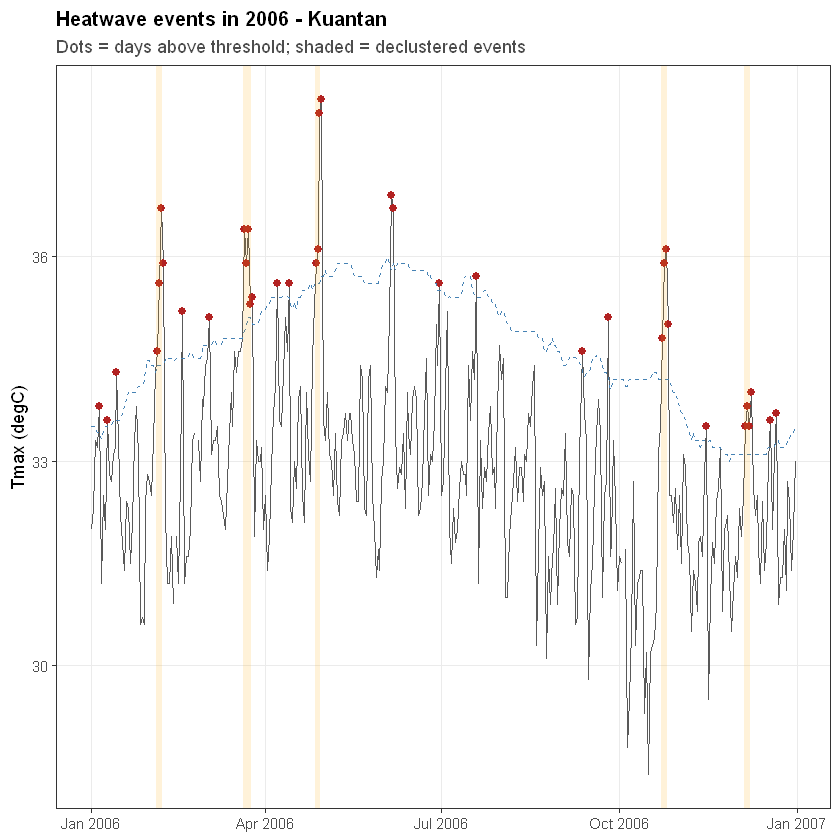

In [11]:
event_year <- as.integer(names(which.max(table(ev$start_year))))
cat("事件最多的年份:", event_year, "\n")

ss  <- s %>% filter(lubridate::year(date) == event_year)
evy <- ev %>% filter(start_year == event_year)

p_year <- ggplot(ss, aes(date, tmax)) +
  geom_line(colour = "grey35", linewidth = 0.5) +
  geom_point(data = subset(ss, exceed), aes(date, tmax),
             colour = "firebrick", size = 1.8) +
  geom_line(aes(y = threshold), colour = "steelblue", linetype = "dashed") +
  geom_rect(data = evy, inherit.aes = FALSE,
            aes(xmin = start_date - 0.5, xmax = end_date + 0.5,
                ymin = -Inf, ymax = Inf),
            fill = "orange", alpha = 0.15) +
  labs(x = NULL, y = "Tmax (degC)",
       title = paste("Heatwave events in", event_year, "-", STATION),
       subtitle = "Dots = days above threshold; shaded = declustered events") +
  theme_paper()

save_fig(p_year, "S03_event_timeline", 7, 4)
p_year

---

## 8. 敏感性：`min_len` × `max_gap`

In [12]:
grid <- expand.grid(min_len = c(2, 3, 5), max_gap = c(0, 2, 5),
                    KEEP.OUT.ATTRS = FALSE)

sens <- do.call(rbind, lapply(seq_len(nrow(grid)), function(i) {
  cfg_i <- CFG
  cfg_i$min_len <- grid$min_len[i]
  cfg_i$max_gap <- grid$max_gap[i]
  e <- extract_events(s, "tmax", defn = "Tmax", cfg = cfg_i)
  if (is.null(e)) return(NULL)
  data.frame(min_len = grid$min_len[i], max_gap = grid$max_gap[i],
             n_events = nrow(e),
             median_duration = median(e$duration),
             mean_intensity = round(mean(e$intensity), 3),
             max_duration = max(e$duration))
}))

print(sens, row.names = FALSE)

 min_len max_gap n_events median_duration mean_intensity max_duration
       2       0      175               3          1.309           10
       3       0       91               4          1.616           10
       5       0       26               5          2.001           10
       2       2      170               3          1.336           14
       3       2       90               4          1.623           13
       5       2       26               5          2.001           13
       2       5      167               3          1.368           18
       3       5       91               4          1.634           15
       5       5       26               5          2.001           13


> 📌 **读这张表的方法**：
> - `min_len` 上升 → 事件数下降、中位时长上升
> - `max_gap` 上升 → 事件数下降、长事件变多
>
> 如果结论（例如 RO3 的 Δτ）在这张表的每一行都保持同号，说明它不依赖于事件定义。**这正是审稿人想看到的稳健性证据。**

---

## 9. 本讲产出

In [13]:
cat("产出：\n")
cat(" ", file.path(PATHS$mfig, "S03_event_timeline.png"), "\n")

产出：


  C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S03_event_timeline.png 


---

## 10. 常见错误

| 错误 | 后果 |
|---|---|
| 不设 `min_len` | 一半事件是单日高温 |
| 不做 declustering | 事件数虚高、时长偏短 |
| 缺测日当 `FALSE` 又做 declustering | 两个事件被缺失数据缝合 |
| intensity 用绝对温度 | 跨站不可比 |
| 事件属性用整个事件窗口的平均值 | 稀释峰值，丢失「极端」信息 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 declustering 会同时「减少事件数」和「增加平均时长」？</summary>

因为它把相邻片段合并了。合并后，原本的两个事件变成一个更长的——分子（总天数）不变或略增，分母（事件数）变小，所以平均时长上升。
</details>

<details>
<summary>Q2：`severity` 和 `intensity × duration` 是一回事吗？</summary>

不是。`severity = Σ(值−阈值)` 只累加正超出量；`intensity × duration` 会把未超标的日子也算进去。只有在事件内部每天都超标时两者才接近。
</details>

<details>
<summary>Q3：如果某站 44 年只有 20 个事件，能拟合 copula 吗？</summary>

勉强。bivariate copula 在 n=20 时参数估计的标准误很大，尾部依赖基本不可估。这就是为什么 S05 会先做「每格事件数」的表，n < 30 的格子直接标注不建模。
</details>

<details>
<summary>Q4：为什么用 `>` 而不是 `>=`？</summary>

用 `>` 时，恰好等于阈值的日子不触发事件，超阈值率更接近名义的 10%。用 `>=` 会略微增加事件数。这个选择要在方法章写明，并保持全篇一致。
</details>

---

## 下一步

**S04 · 三个定义**：湿球温度到底是什么，为什么 Twmax 而不是 Twmin/Twmean，以及三套定义如何并行。